# 04 - Exploratory Data Analysis

**Goal:** Explore the target and its relationship with the information available at opening. This helps guide feature selection and the data split. The analysis is based on the incident table from notebook 03. Variables recorded after opening are only examined at the end for reference.

## 1. Loading

In [10]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # to import src from the notebooks folder

import numpy as np
import pandas as pd
from src import config, plots as pl

pd.set_option("display.max_columns", 50, "display.width", 200)
TARGET = config.TARGET
t = pd.read_csv(config.INCIDENT_FILE, parse_dates=["opened_at", "closed_at"])
assert t.shape == (24905, 22)    # table of notebook 03
target = t[TARGET]


def by_group(col, min_n=1):
    """Number of incidents and resolution time (hours) for each value of a column."""
    out = t.groupby(col, dropna=False, observed=True)[TARGET].agg(
        n="size", median="median", mean="mean", p90=lambda s: s.quantile(0.9)).round(1)
    return out[out["n"] >= min_n]


print(t.shape)

(24905, 22)


## 2. Resolution time

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
resolution_hours,24905.0,167.3,517.8,0.0,0.3,16.1,141.1,361.1,673.9,2759.9,8070.2


exactly 0 hours     6.3
under 1 hour       36.3
under 24 hours     54.6
over 7 days        21.5
over 30 days        4.6

skewness: 7.1 | skewness of log(1 + hours): 0.3


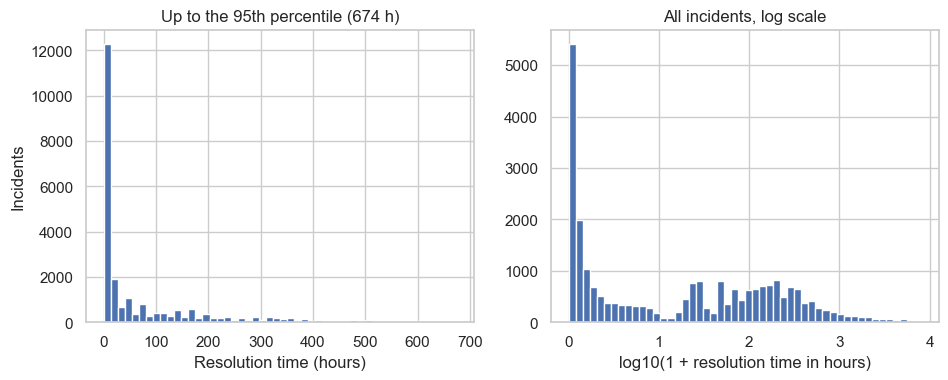

In [11]:
display(target.describe(percentiles=[.25, .5, .75, .9, .95, .99]).round(1).to_frame("resolution_hours").T)

shares = pd.Series({
    "exactly 0 hours": target.eq(0).mean(), "under 1 hour": target.lt(1).mean(), "under 24 hours": target.lt(24).mean(),
    "over 7 days": target.gt(168).mean(), "over 30 days": target.gt(720).mean()}) * 100
print(shares.round(1).to_string())
print("\nskewness:", round(target.skew(), 1), "| skewness of log(1 + hours):", round(np.log1p(target).skew(), 1))
pl.plot_target_distribution(target);

The target is highly skewed (7.1): the median is 16.1 hours, while the mean is 167.3 hours. About 36.3% of incidents are resolved in under one hour, while 21.5% take more than seven days. After a log transform, the skewness drops to 0.3.

This means the model must handle both short and long incidents. The few very long cases can strongly affect RMSE, so testing a log transform during tuning is worth considering.

## 3. Features known at opening

### 3.1 Priority, impact, urgency

,n,median,mean,p90
priority,,,,
1 - Critical,185,51.4,189.9,467.0
2 - High,311,49.2,162.8,381.7
3 - Moderate,23677,15.9,164.9,359.7
4 - Low,732,1.0,239.2,387.6


,n,median,mean,p90
impact,,,,
1 - High,286,49.0,184.6,482.4
2 - Medium,23902,16.4,165.5,360.6
3 - Low,717,0.8,219.8,358.1


,n,median,mean,p90
urgency,,,,
1 - High,395,52.7,172.4,382.6
2 - Medium,23835,16.1,165.1,360.2
3 - Low,675,0.7,240.0,373.0


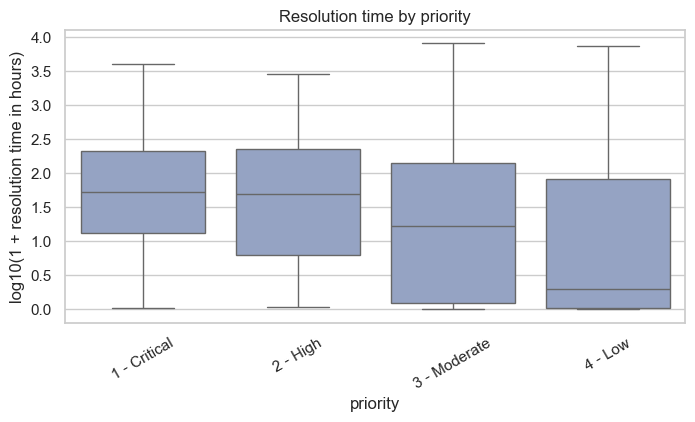

In [12]:
display(by_group("priority"))
pl.plot_box_by_group(t, "priority", TARGET, order=sorted(t["priority"].unique()))
display(by_group("impact"))
display(by_group("urgency"))

Critical and High incidents take longer to resolve (51.4 h and 49.2 h) than Moderate (15.9 h) and Low (1.0 h). This may be because more complex incidents receive higher priority.

Impact and urgency show similar patterns because they determine priority. These three features contain similar information. Priority is useful, but does not directly indicate resolution time.

### 3.2 Contact type and notification

In [13]:
display(by_group("contact_type"))
by_group("notify")

,n,median,mean,p90
contact_type,,,,
Direct opening,3,17.3,22.0,41.5
Email,61,146.0,137.2,315.8
Phone,24680,15.6,166.5,360.3
Self service,161,48.2,298.4,720.1


,n,median,mean,p90
notify,,,,
Do Not Notify,24869,15.9,167.2,361.4
Send Email,36,178.3,188.7,331.1


`Phone` represents 99.1% of incidents. The other contact types are very rare. `Email` and `Self service` have longer resolution times. Since these columns have very little variation, rare values will be grouped in the pipeline. `notify` is excluded because almost all incidents have the same value.

### 3.3 Category

categories: 56 | the 10 largest cover 74.8 % of the incidents


,n,median,mean,p90
category,,,,
Category 42,3628,0.4,93.4,163.7
Category 26,3267,1.5,73.8,236.9
Category 53,2655,24.4,126.5,330.4
Category 46,2243,48.3,283.7,739.8
Category 32,1495,0.3,52.6,172.1
Category 9,1141,41.4,146.8,363.2
Category 37,1135,19.2,119.4,307.2
Category 23,1071,44.5,156.6,424.9
Category 20,1067,0.9,57.3,188.2


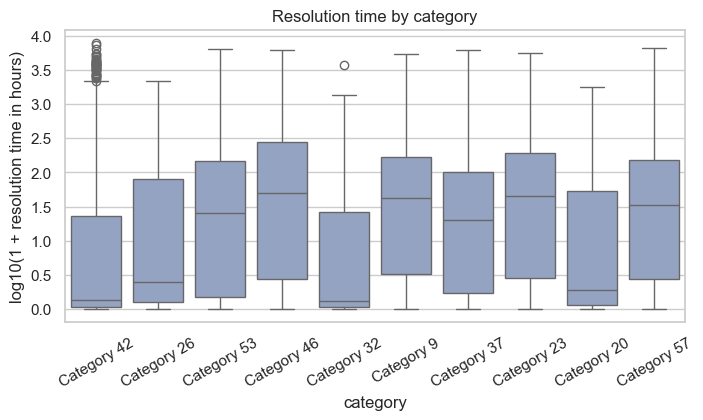

In [14]:
cat = by_group("category")
cat = cat[cat.index.notna()].sort_values("n", ascending=False)
print("categories:", len(cat), "| the 10 largest cover", round(cat["n"].head(10).sum() / len(t) * 100, 1), "% of the incidents")
display(cat.head(10))
top = list(cat.index[:10])
pl.plot_box_by_group(t[t["category"].isin(top)], "category", TARGET, order=top)

There are 56 categories, and the 10 most common represent 74.8% of incidents. Resolution times vary a lot between them: some have a median below 1 hour, while Category 46 reaches 48.3 hours. Category is therefore a useful feature, but it cannot explain everything.

### 3.4 Columns with many values

For people, groups and locations I look at how many values there are and how much the largest ones cover.

In [15]:
rows = []
for c in ["location", "assignment_group", "subcategory", "u_symptom", "opened_by", "caller_id", "sys_created_by"]:
    vc = t[c].value_counts()
    rows.append({"column": c, "n_values": len(vc), "% missing": round(t[c].isna().mean() * 100, 1),
                 "top 10 cover (% incidents)": round(vc.head(10).sum() / len(t) * 100, 1),
                 "values in < 5 incidents": int((vc < 5).sum())})
display(pd.DataFrame(rows).set_index("column"))

print("assignment_group, 10 largest groups:")
by_group("assignment_group").sort_values("n", ascending=False).head(10)

,n_values,% missing,top 10 cover (% incidents),values in < 5 incidents
column,,,,
location,218,0.2,80.2,95
assignment_group,69,3.6,73.3,8
subcategory,246,0.3,67.6,90
u_symptom,500,23.0,54.7,307
opened_by,206,2.9,64.0,90
caller_id,5242,0.0,4.8,3485
sys_created_by,185,46.1,32.0,85


assignment_group, 10 largest groups:


,n,median,mean,p90
assignment_group,,,,
Group 70,12781,0.6,72.0,209.1
Group 20,1367,56.6,210.4,483.5
NaN,905,71.7,151.1,361.1
Group 25,764,78.0,173.5,382.8
Group 24,698,20.1,102.0,213.4
Group 64,622,0.0,14.6,43.1
Group 65,500,40.1,200.3,401.5
Group 55,416,24.9,204.1,476.2
Group 66,389,156.5,414.4,983.5


`caller_id` has too many different values, most appearing in fewer than 5 incidents, so I exclude it. Other columns also contain rare values, which will be grouped in the pipeline using the training set only.

`assignment_group` has only 69 values and shows clear differences in resolution time. For example, Group 70 represents 51% of incidents, with a median of 0.6 h, while Group 66 has a median of 156.5 h. I keep the group from the first event.

### 3.5 Is a missing value informative?

Some columns are empty for many incidents. I check if the incidents with an empty value are resolved faster or slower, and if the empty values depend on the period.

In [16]:
rows = []
for c in ["sys_created_by", "u_symptom", "opened_by", "assignment_group"]:
    miss = t[c].isna()
    rows.append({"column": c, "% missing": round(miss.mean() * 100, 1),
                 "median if missing": round(t.loc[miss, TARGET].median(), 1),
                 "median if present": round(t.loc[~miss, TARGET].median(), 1)})
display(pd.DataFrame(rows).set_index("column"))

month = t["opened_at"].dt.to_period("M")
print("% of incidents with sys_created_by missing, by month of opening:")
(t["sys_created_by"].isna().groupby(month).mean() * 100).round(1).to_frame("% missing").T

,% missing,median if missing,median if present
column,,,
sys_created_by,46.1,0.4,48.5
u_symptom,23.0,20.5,13.0
opened_by,2.9,52.0,13.8
assignment_group,3.6,71.7,13.4


% of incidents with sys_created_by missing, by month of opening:


opened_at,2016-02,2016-03,2016-04,2016-05,2016-06,2016-07,2016-08,2016-09,2016-10,2016-11,2016-12,2017-01,2017-02
% missing,30.9,34.2,49.6,56.9,20.0,28.6,33.3,41.7,37.5,50.0,21.6,46.8,100.0


Missing values are also important. For `sys_created_by`, incidents with a missing value have a median of 0.4 h, compared with 48.5 h when the value is present. Similar differences appear in other columns.

Missing `sys_created_by` varies by month (20% to 57%), so I keep it as a separate category. Its absence may be related to how the incident was created, but the reason is unknown. I will also test the model without this feature.

## 4. Time of opening

,n,median,mean,p90
month,,,,
2016-02,207,53.4,316.8,666.9
2016-03,8993,49.4,220.2,473.0
2016-04,7933,2.7,137.8,288.6
2016-05,7508,2.0,127.6,291.1
2016-06,5,26.6,1086.0,3224.9
2016-07,14,34.8,279.5,683.3
2016-08,15,145.2,519.9,1568.3
2016-09,12,64.4,433.4,702.5
2016-10,16,111.0,652.4,2302.7


,n,median,mean,p90
opened_at,,,,
Monday,5942,16.9,152.2,355.7
Tuesday,4948,17.7,158.7,358.0
Wednesday,4880,18.3,194.6,458.9
Thursday,4105,14.9,179.2,388.1
Friday,3829,8.8,186.2,407.5
Saturday,638,1.8,69.1,212.5
Sunday,563,1.4,60.6,199.2


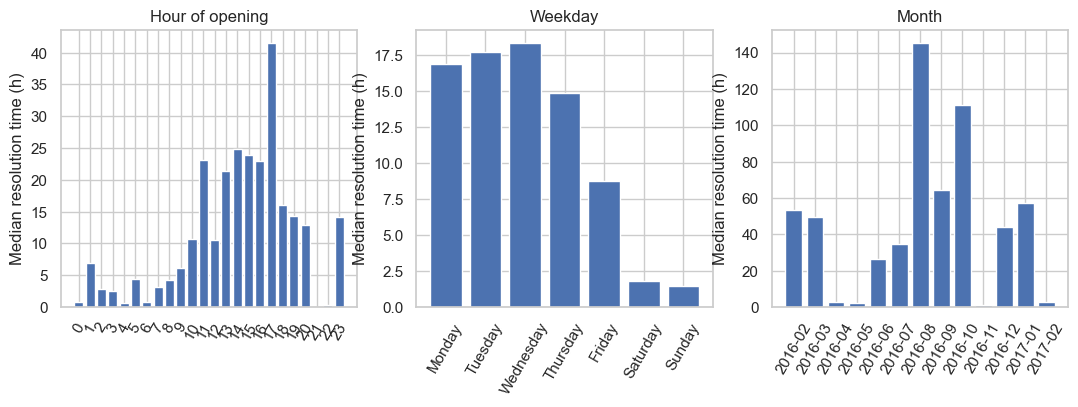

In [17]:
pl.plot_median_by_time(t, TARGET)
t["month"] = t["opened_at"].dt.to_period("M").astype(str)
display(by_group("month"))
by_group(t["opened_at"].dt.day_name()).reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])

Opening time affects resolution time. Incidents opened during the week take longer to resolve than those opened at weekends. The hour also makes a difference.

The main issue is the date distribution. Almost all incidents (98.9%) were opened between February and May 2016. Resolution times also change a lot between these months. Later months have very few incidents.

This makes a date-based split more difficult than a random split, but it gives a more realistic evaluation. I will check the weekly trends before choosing the split dates. The month will not be used as a feature.

## 5. Variables that appear after the opening (information only)

`reassignment_count`, `reopen_count` and `n_events` are known only after the opening, so they are **not** features. I look at them to understand what makes an incident long.

In [18]:
post = ["reassignment_count", "reopen_count", "n_events"]
display(t[post + [TARGET]].corr(method="spearman")[TARGET].drop(TARGET).round(2).to_frame("Spearman with target"))

t["reassignments"] = pd.cut(t["reassignment_count"], [-1, 0, 1, 2, 4, 100], labels=["0", "1", "2", "3-4", "5+"])
by_group("reassignments")

,Spearman with target
reassignment_count,0.56
reopen_count,0.11
n_events,0.77


,n,median,mean,p90
reassignments,,,,
0,13537,0.4,84.2,173.7
1,6237,42.1,173.6,356.2
2,2283,103.0,315.6,608.4
3-4,1929,163.1,389.2,746.5
5+,919,292.1,513.2,985.7


`n_events` and `reassignment_count` are strongly related to resolution time (Spearman 0.77 and 0.56). Longer incidents usually have more updates and reassignments. These columns describe what happens after opening, so they are excluded from the model and used only for error analysis.

## Conclusions for the next step

- **Target:** Highly skewed. I keep MAE and RMSE in hours and test a log transform.
- **Features kept:** `priority`, `impact`, `urgency`, `category`, `subcategory`, `assignment_group`, `location`, `u_symptom`, `contact_type`, `opened_by`, `sys_created_by`, opening hour and weekday.
- **Excluded:** `caller_id`, `notify`, `cmdb_ci`, month and all columns recorded after opening.
- **Rare values:** Grouped in the pipeline using the training set only.
- **Split:** Based on opening date. Weekly changes will be checked in the next notebook.
- **Further tests:** Models with and without `sys_created_by`, and with and without incidents created already `Resolved`.